In [1]:
import xtrack as xt
import numpy as np

In [10]:
p0c = 1e9            # reference momentum [eV/c]

k1 = 1;
k2 = -1;
L_q=1.0;
L_drift1=1.0
L_drift2=2.0

env = xt.Environment()
env.particle_ref = xt.Particles(p0c=p0c, mass0=xt.ELECTRON_MASS_EV)

env['qf.k1'] = 1
env['qd.k1'] = -1
env['l'] = 1.0
env['betx0'] = 100.0
env['bety0'] = 100.0
env['alfx0'] = 0
env['alfy0'] = 0

env.new('start', xt.Marker)
env.new('qf', xt.Quadrupole, length=L_q, k1='qf.k1')   # half QF
env.new('qd', xt.Quadrupole, length=L_q, k1='qd.k1')
env.new('d1', xt.Drift, length='l')
env.new('d2', xt.Drift, length=L_drift2)
env.new('focus', xt.Marker)
env.new('d3', xt.Drift, length=L_drift2)
 
cell = env.new_line(components=[
    env.place('start'),
    env.place('qf'),
    env.place('d1'),
    env.place('qd'),
    env.place('d2'),
    env.place('focus'),
    env.place('d3')
])

line = env.new_line(components=[cell])
line.build_tracker()

init = xt.TwissInit(
    line=line,
    element_name='start',   # where the init conditions apply
    betx=env['betx0'], 
    alfx=env['alfx0'],
    bety=env['bety0'], 
    alfy=env['alfy0'],
    dx=0.0, dpx=0.0,
    dy=0.0, dpy=0.0,
)

opt = line.match(
    start='start', end='focus',
    init=init,
    vary=xt.VaryList(['betx0', 'bety0', 'alfx0','alfy0']),
    targets=[
        xt.TargetSet(at='focus', alfy=0, alfx=0),
        
    ],
    n_steps_max=10000
)

tw = line.twiss4d(init=init)

                                             
Optimize - start penalty: 7988                              
Matching: model call n. 110002 penalty = 7.9883e+03              
Optimize - end penalty:  7988.26                            


Could not find point within tolerance.
Matching: model call n. 110003 penalty = 7.9883e+03              



RuntimeError: Could not find point within tolerance.

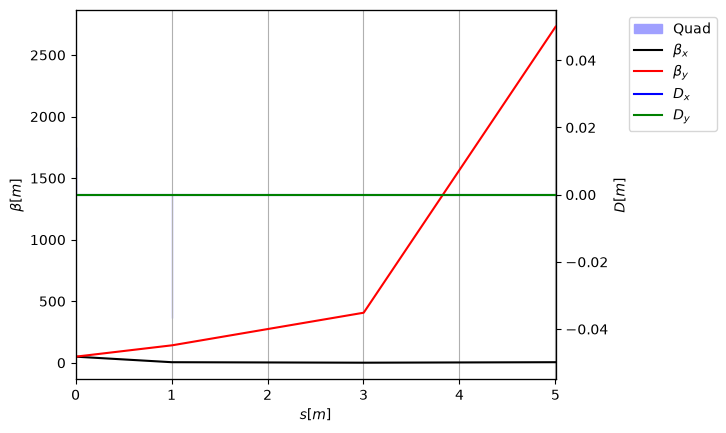

In [75]:
tw.plot()

In [3]:
env = xt.Environment()

In [7]:
env['betx0'] = 10.0

In [9]:
type(env.ref['betx0'])

xdeps.refs.ItemRef

In [11]:
import numpy as np
import xtrack as xt
 
# ---------------------------------------------------------------- parameters
beta_star = 0.1      # m, target beta at the focus
l_quad = 0.5         # m, quadrupole length
p0c = 10e9           # eV, reference momentum
 
# ------------------------------------------------- environment and variables
env = xt.Environment()
 
env['kq1'] = 0.5     # 1/m^2, initial guesses (QF first, then QD)
env['kq2'] = -0.5
env['l_gap'] = 1.0   # m, distance between the two quads
env['l_focus'] = 2.0 # m, distance from second quad to focus
 
env.new('start', xt.Marker)
env.new('d0', xt.Drift, length=2.0)
env.new('q1', xt.Quadrupole, length=l_quad, k1='kq1')
env.new('d_gap', xt.Drift, length='l_gap')
env.new('q2', xt.Quadrupole, length=l_quad, k1='kq2')
env.new('d_focus', xt.Drift, length='l_focus')
env.new('focus', xt.Marker)
 
line = env.new_line(components=[
    'start', 'd0', 'q1', 'd_gap', 'q2', 'd_focus', 'focus'])
line.particle_ref = xt.Particles(p0c=p0c, mass0=xt.PROTON_MASS_EV)
line.build_tracker()
 
# ---------------------------------------------------- initial optics (input)
init = xt.TwissInit(line=line, element_name='start',
                    betx=10., alfx=0., bety=10., alfy=0.)
 
tw0 = line.twiss(start='start', end='focus', init=init)
print('Before matching:')
tw0.rows['focus'].cols['betx bety alfx alfy'].show()
 
# ------------------------------------------------------------------- match
opt = line.match(
    start='start', end='focus', init=init,
    vary=[
        xt.Vary('kq1', step=1e-6, limits=(0, 5)),        # focusing in x
        xt.Vary('kq2', step=1e-6, limits=(-5, 0)),       # defocusing in x
        xt.Vary('l_gap', step=1e-6, limits=(0.2, 3.0)),
        xt.Vary('l_focus', step=1e-6, limits=(0.5, 6.0)),
    ],
    targets=[
        xt.TargetSet(at='focus', betx=beta_star, bety=beta_star, tol=1e-6),
        xt.TargetSet(at='focus', alfx=0, alfy=0, tol=1e-6),
    ],
    n_steps_max=100,
)
 
# ------------------------------------------------------------------ results
opt.target_status()
opt.vary_status()
 
tw = line.twiss(start='start', end='focus', init=init)
print('\nAfter matching:')
tw.rows['focus'].cols['betx bety alfx alfy'].show()
print(f"kq1 = {env['kq1']:.5f} 1/m^2, kq2 = {env['kq2']:.5f} 1/m^2")
print(f"l_gap = {env['l_gap']:.4f} m, l_focus = {env['l_focus']:.4f} m")
 
# Optional: beam size along the line for a given geometric emittance
gemit = 1e-9  # m rad
sigma_x = np.sqrt(gemit * tw.betx)
sigma_y = np.sqrt(gemit * tw.bety)
print(f"sigma_x at focus = {sigma_x[-1]*1e6:.2f} um, "
      f"sigma_y at focus = {sigma_y[-1]*1e6:.2f} um")
 
# Optional plot
try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots()
    ax.plot(tw.s, tw.betx, label=r'$\beta_x$')
    ax.plot(tw.s, tw.bety, label=r'$\beta_y$')
    ax.set_xlabel('s [m]')
    ax.set_ylabel(r'$\beta$ [m]')
    ax.set_yscale('log')
    ax.legend()
    plt.savefig('doublet_optics.png', dpi=150)
except ImportError:
    pass

Before matching:
name           betx          bety          alfx          alfy
focus       5.13352       17.4336     -0.299494      0.745853
                                             
Optimize - start penalty: 19.76                             
Matching: model call n. 93 penalty = nan                     

/Users/stewart.boogert/venv/bdsim/lib/python3.14/site-packages/xdeps/optimize/jacobian.py:118: RuntimeWarning: divide by zero encountered in divide
  this_xstep = this_xstep * (self.x[ii] - limits[ii][0]) / this_xstep[ii]
/Users/stewart.boogert/venv/bdsim/lib/python3.14/site-packages/xdeps/optimize/jacobian.py:118: RuntimeWarning: invalid value encountered in divide
  this_xstep = this_xstep * (self.x[ii] - limits[ii][0]) / this_xstep[ii]
/Users/stewart.boogert/venv/bdsim/lib/python3.14/site-packages/xdeps/optimize/jacobian.py:122: RuntimeWarning: invalid value encountered in divide
  this_xstep = this_xstep * (self.x[ii] - limits[ii][1]) / this_xstep[ii]
/Users/stewart.boogert/venv/bdsim/lib/python3.14/site-packages/xtrack/twiss/lattice_functions_from_W.py:188: RuntimeWarning: invalid value encountered in divide
  v1[:, ii] /= nux
/Users/stewart.boogert/venv/bdsim/lib/python3.14/site-packages/xtrack/twiss/lattice_functions_from_W.py:189: RuntimeWarning: invalid value encountered in di

Matching: model call n. 48122 penalty = nan              

KeyboardInterrupt: 